# 01 — The dataset: build it, check it, look at it

Runs here, on a laptop: no GPU needed. It fetches the zone's archives, builds the index (one row per tile of the
deepest level that has its neighbours and its parent context), checks every parent/child pair, and opens the
before/after browser. Then it pushes the index to the bucket for `02_inference` (GPU) to read.

Two families of inputs on the same tiles, at ×2, ×4 and ×8:

- **synthetic** — the tile damaged by us (reduction, blur, noise, JPEG at the source's quality), the control;
- **levels** — the real ancestor 1, 2 or 3 zooms up (z18, z17, z16), brought to the child's colours, then checked:
  same detail and little remaining colour difference, or it is *another acquisition* and is flagged, never measured.

Nothing image-sized is written: inputs are rebuilt on demand from the archives, deterministically.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from overzoom.archives import fetch_listed, load_zone
from overzoom.config import Lab
from overzoom.dataset import Dataset, DatasetSpec, build_index
from overzoom.view import browse

lab = Lab.load(Path("../lab.json"))
NAME = "luchon-z19-v3"
spec = DatasetSpec(zoom=19)
print(lab.data, "→", lab.remote)

/Users/laurentvaldes/Projects/tuile-image-lab/lab/overzoom/data → s3://tuile-notebooks-057321054380/overzoom


## 1. The zone's archives, merged newest first

In [2]:
archives = fetch_listed(lab.url_list, lab.data / "archives")
store, infos = load_zone(archives)
print(f"{len(archives)} archives, {len(store)} tiles")
pd.DataFrame([(i.key, i.tiles, i.min_zoom, i.max_zoom) for i in infos], columns=["archive", "tiles", "min z", "max z"])

21 archives, 65924 tiles


,archive,tiles,min z,max z
0,202609-000001790253136886611365-0e302ced7abf99...,85,10,13
1,202609-000001790281913103492870-a3d570b296cbdb...,7748,14,19
2,202609-000001790281285302688762-bc86c899d3889c...,232,15,19
3,202609-000001790281292620542106-132366fec259dd...,8,14,14
4,202609-000001790281293119785485-6e1b344b22c5ad...,19,14,15
5,202609-000001790281294710364817-66b6a390e4282e...,554,15,19
6,202609-000001790281295544962288-bbc857f793dcb0...,163,14,16
7,202609-000001790281329310031616-9cd7978bba7a37...,1,14,14
8,202609-000001790281413988401393-cfdb1ed6b0acef...,2403,15,19
9,202609-000001790281423574983948-ec75aa35b36e77...,20,15,16


## 2. The index

Every textured tile of z19 with its neighbours (for the halo) and its ancestors' context, and the check of each pair.

In [3]:
saved = lab.data / "datasets" / NAME
if (saved / "index.parquet").exists():  # already built: load it, to browse at once
    ds = Dataset.load(saved, store)
    spec, index = ds.spec, ds.index
    print("loaded", saved)
else:
    index = build_index(store, spec)
    ds = Dataset(store, spec, index)
print(f"{len(ds)} samples")
print(pd.DataFrame({lv: index[f"{lv}_class"].value_counts() for lv in spec.levels}).fillna(0).astype(int))
print(f"{len(ds) * len(spec.inputs)} comparisons in all")

loaded /Users/laurentvaldes/Projects/tuile-image-lab/lab/overzoom/data/datasets/luchon-z19-v3
13259 samples
          z18    z17   z16
other       0      0  1943
same    10156  10156  8244
tinted   3103   3103  3072
198885 comparisons in all


## 3. Do the levels match?

Per ancestor, per pair: the correlation of the luminance detail (blind to colour; unrelated ground gives about 0),
the tint difference as served (ΔE of the mean colours: above the line, the pair is *tinted*), and the colour left
after equalisation (above the line, *another acquisition*). Set the thresholds by looking at the pairs in the browser
below, not on the histograms.

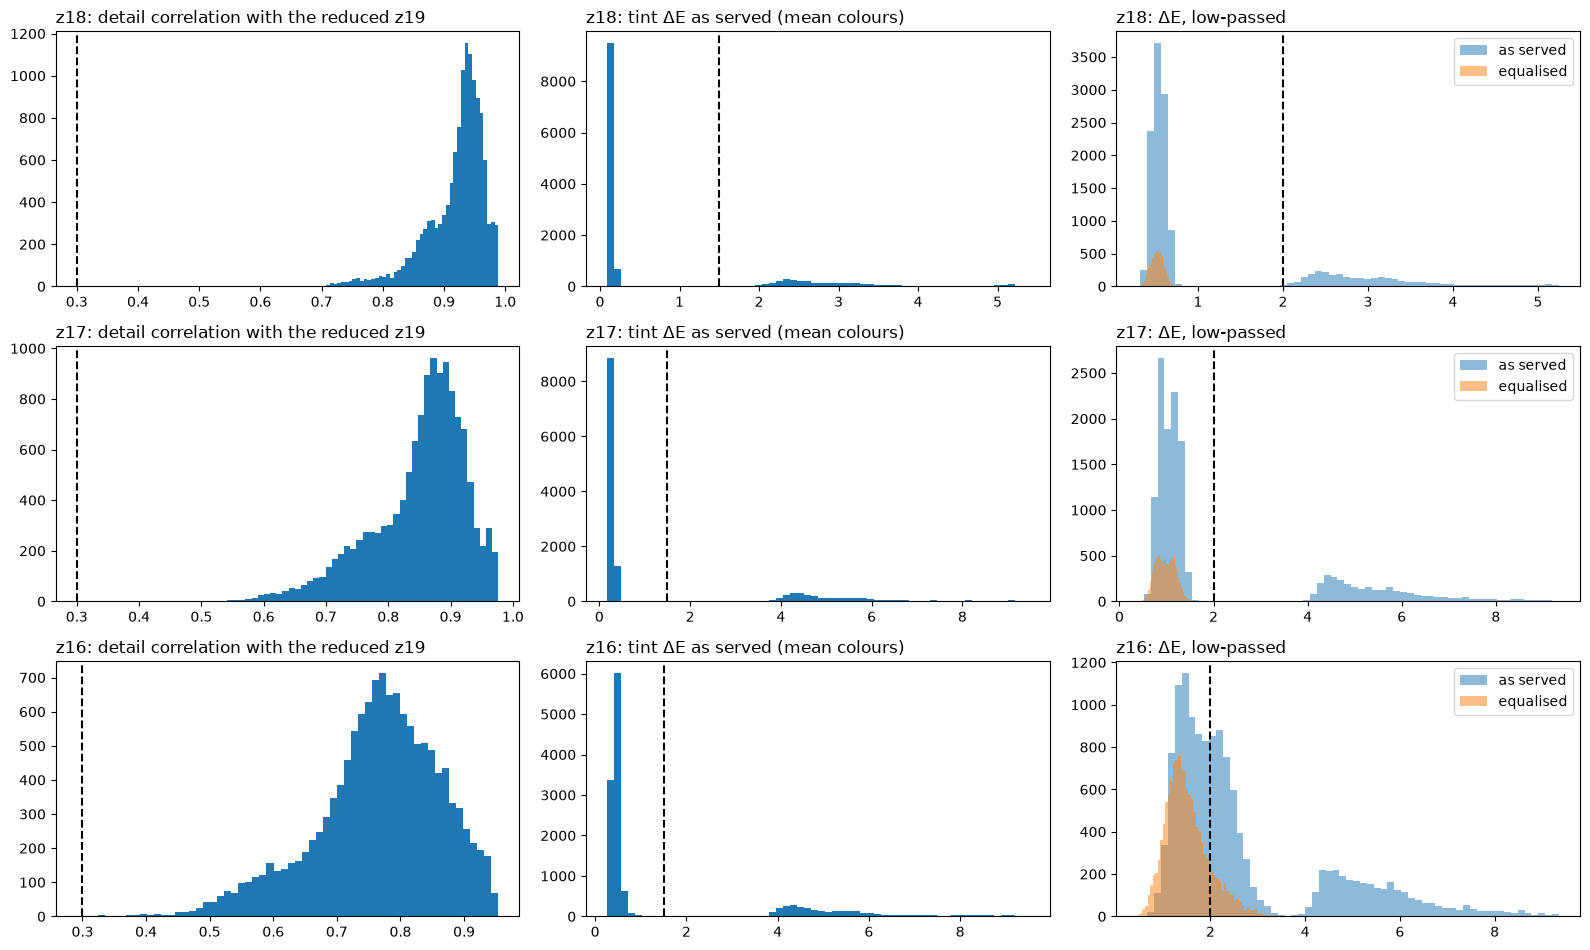

In [4]:
fig, ax = plt.subplots(len(spec.levels), 3, figsize=(16, 3.2 * len(spec.levels)), squeeze=False)
for row, lv in enumerate(spec.levels):
    ax[row, 0].hist(index[f"{lv}_structure"], 60)
    ax[row, 0].axvline(spec.policy.min_structure, ls="--", c="k")
    ax[row, 0].set_title(f"{lv}: detail correlation with the reduced z{spec.zoom}", loc="left")
    ax[row, 1].hist(index[f"{lv}_cast_raw"], 60)
    ax[row, 1].axvline(spec.policy.max_cast, ls="--", c="k")
    ax[row, 1].set_title(f"{lv}: tint ΔE as served (mean colours)", loc="left")
    ax[row, 2].hist(index[f"{lv}_delta_e_raw"], 60, alpha=0.5, label="as served")
    ax[row, 2].hist(index[f"{lv}_delta_e"], 60, alpha=0.5, label="equalised")
    ax[row, 2].axvline(spec.policy.max_delta_e, ls="--", c="k")
    ax[row, 2].set_title(f"{lv}: ΔE, low-passed", loc="left")
    ax[row, 2].legend()
plt.tight_layout()
plt.show()

## 4. Before / after

Filter by input family and by level status; sort by texture or by pair score (the worst pairs first with
`level_ssim_y`). *Blink* alternates before and after in place: the fastest way to see what changed.

In [5]:
browse(ds, limit=20000)

## 5. Save and share

The index and its manifest go to the bucket; the GPU machine fetches the same archives and rebuilds the same inputs.

In [7]:
out = lab.data / "datasets" / NAME
ds.save(out, [p.name for p in archives])
lab.push(out, f"datasets/{NAME}")
print(out, "→", f"{lab.remote}/datasets/{NAME}")

/Users/laurentvaldes/Projects/tuile-image-lab/lab/overzoom/data/datasets/luchon-z19-v3 → s3://tuile-notebooks-057321054380/overzoom/datasets/luchon-z19-v3
